# QE015: Chaos as a Quantum Sensor

**How precisely can a quantum sensor measure a magnetic field, and can making it chaotic help?**

A magnetometer made of atomic spins measures a field by how far the spins precess. Quantum mechanics sets a limit on
how precisely this can ever be read off: the **quantum Fisher information** (QFI). Ordinary uncorrelated spins reach
the **standard quantum limit**; exotic entangled states could reach the **Heisenberg limit**, but they are fragile and
hard to make.

This exercise explores a surprising alternative: kick the spins periodically so that their dynamics becomes
**chaotic**. Chaos stretches small differences exponentially, including the tiny difference a magnetic field makes.

* **Part A (one exact answer, Euler-style):** compute the QFI of a kicked spin sensor exactly.
* **Part B1:** QFI against time for regular and chaotic sensors, between the standard and Heisenberg limits.
* **Part B2:** which starting states work best? A map of sensing power next to the classical chaos map.
* **Part B3:** does the advantage grow with the size of the sensor?
* **Part B4:** add noise. Does chaos still help?
* **Animation:** the quantum state spreading over the sphere, regular versus chaotic.

### Words used in this notebook

| term | meaning |
|---|---|
| **spin j** | a collection of $N = 2j$ spin-½ atoms acting together; its state lives on a sphere |
| **J_x, J_y, J_z** | the total spin along each axis |
| **coherent spin state** | all atoms pointing the same way; the most classical, unentangled state |
| **precession** | rotation of the spin about the field direction; the angle θ per step is what we want to measure |
| **kick (torsion)** | a brief nonlinear pulse $e^{-i\frac{k}{2j}J_y^2}$ that twists the sphere; k is its strength |
| **kicked top** | precession plus periodic kicks, a classic model of quantum chaos |
| **chaos** | dynamics where nearby starting points separate exponentially fast |
| **quantum Fisher information F** | the maximum information about θ any measurement can extract; precision is limited by $\Delta\theta \ge 1/\sqrt{M F}$ for M repetitions (the **quantum Cramér–Rao bound**) |
| **standard quantum limit (SQL)** | the best F with unentangled atoms and plain precession: $F = 2j\,n^2 = N n^2$ after n steps |
| **Heisenberg limit (HL)** | the ultimate F for N atoms: $F = N^2 n^2$, requiring maximal entanglement |
| **gain** | F divided by the SQL; above 1 means better than any unkicked classical-state sensor |
| **Husimi function** | a picture of a quantum spin state as a probability cloud on the sphere |
| **Poincaré map** | the classical picture: where a classical spin vector lands after each step; regular motion traces curves, chaos fills areas |
| **dephasing noise** | random fluctuations of the precession angle that blur the state |

This notebook needs `numpy`, `scipy`, `pandas` and `matplotlib` (Pillow for the GIF comes with matplotlib). It runs in
about two minutes and writes one GIF animation next to itself.

> **Report version.** This copy shows the text, results, plots and animation only. The full runnable notebook with all code is `QE015_Chaos_as_a_Quantum_Sensor.ipynb` in the same folder.

## 1. The sensor

A spin $j$ is described in the basis $|j, m\rangle$, $m = j, \dots, -j$. One step of the sensor is

$$U(\theta) = \underbrace{e^{-i\frac{k}{2j}J_y^2}}_{\text{kick}}\;\underbrace{e^{-i\theta J_z}}_{\text{precession}} .$$

The field to be measured sets the precession angle θ per step; its true value is $\theta = 0.1$. With $k = 0$ this is
an ordinary magnetometer. The sensor starts in a coherent spin state, with all atoms pointing in one direction.

**Computing the QFI exactly.** For a pure state, $F = 4\big(\langle\partial_\theta\psi|\partial_\theta\psi\rangle -
|\langle\psi|\partial_\theta\psi\rangle|^2\big)$. The derivative is carried along step by step with the product rule,
$\partial_\theta\psi_{n+1} = U\,\partial_\theta\psi_n + (\partial_\theta U)\,\psi_n$, where
$\partial_\theta U = e^{-i\frac{k}{2j}J_y^2}(-iJ_z)\,e^{-i\theta J_z}$. No finite differences, no approximation.

coherent state +x: <J>/j = [1. 0. 0.]
coherent state +y: <J>/j = [0. 1. 0.]
coherent state +z: <J>/j = [0. 0. 1.]


## Part A: the information in a chaotic sensor

**Task:** take $j = 10$ ($N = 20$ atoms), kick strength $k = 6$, precession $\theta = 0.1$ per step, and the coherent
state pointing along $+x$. After $n = 20$ steps, compute the quantum Fisher information $F$ and report

$$A = \lfloor 10^3 \cdot F \rfloor .$$

*Check values:* after one step $F = 2j = 20$ exactly (the kick comes after the precession, so it cannot add
information yet). Without kicks ($k = 0$) the state stays perpendicular to the field and $F = 2j\,n^2 = 8000$ after
20 steps.

check, one step      : F = 20.000000000
check, no kicks n=20 : F = 8000.000000
kicked, n = 20       : F = 14186.139855   gain over the SQL: 1.7733
finite-difference check: F = 14186.1398

ANSWER  A = 14186139


With $N = 20$ unentangled atoms the chaotic sensor carries 1.77 times more information than the best plain
magnetometer, without any entanglement in the input.

## Part B1: information against time

For a larger sensor ($j = 50$, 100 atoms), follow $F$ over 40 steps for no kicks, weak kicks (regular dynamics) and
strong kicks (chaotic), starting from a well-placed state (chosen from the map in B2). The grey band runs from the SQL
($N n^2$) up to the Heisenberg limit ($N^2 n^2$).

gain maps computed in 0 s
best starting direction for k = 6: polar 166 deg, azimuth -48 deg, gain 20.2 after 20 steps


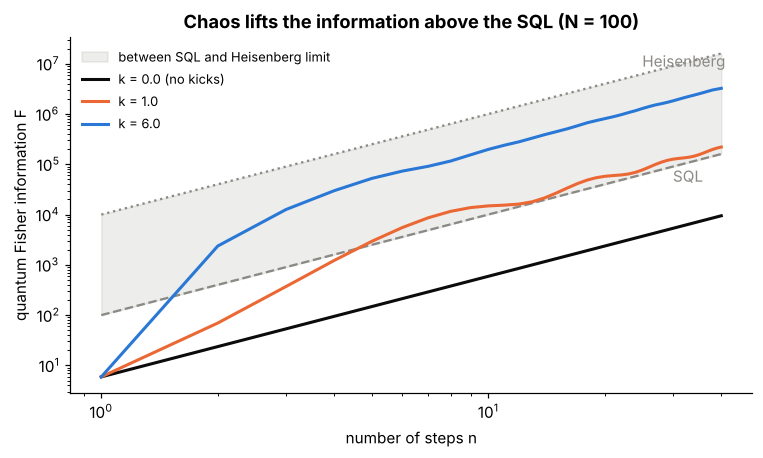

{'k = 0.0': 'gain at n = 20: 0.1', 'k = 1.0': 'gain at n = 20: 1.4', 'k = 6.0': 'gain at n = 20: 20.2'}


## Part B2: where should the sensor start?

Left: the classical picture. A classical spin vector follows the same kicked dynamics, and plotting where it lands after
each step (a **Poincaré map**) shows regular islands, where points trace closed curves, and a chaotic sea, where they
scatter. Right: the quantum gain after 20 steps for every starting direction. The map uses an equal-area projection:
horizontal = azimuth, vertical = cos(polar angle).

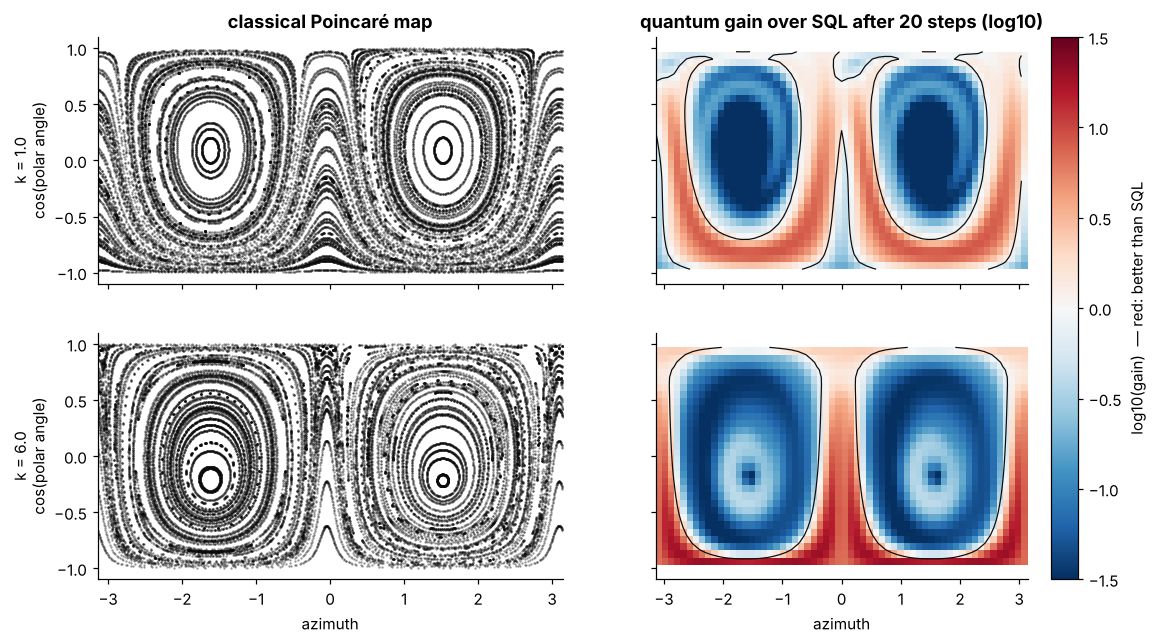

{'k = 1.0': 'fraction of starting directions beating the SQL: 46%, best gain 8.6', 'k = 6.0': 'fraction of starting directions beating the SQL: 31%, best gain 20.2'}


The two maps line up. Inside the large **regular islands** (closed curves on the left) the state just circles around
and the gain stays far below 1. Outside them, near the poles and along the boundary between the islands, the dynamics
stretches the state, and the gain rises above the SQL. Even weak kicks help there: the nonlinear twisting alone shears
the state. Strong kicks make that outer region chaotic and give the largest gains (about 20 for 100 atoms), but large
islands survive because the precession per step is small, so a smaller share of starting directions benefits. As
Fiderer and Braun found, the best starting points sit in the chaotic region next to the islands. Notice also that the
best chaotic starting point lies near a pole, where a plain magnetometer is almost blind (gain 0.1 in B1).

## Part B3: does it scale?

Repeat the search for the best starting direction at $k = 6$ and 20 steps for growing sensors.

computed in 1 s


,best gain over SQL,median gain,Heisenberg limit (gain = N)
atoms N = 2j,,,
10,1.76,0.41,10
20,4.40,0.24,20
40,8.86,0.22,40
100,20.12,0.19,100
200,33.41,0.20,200


The best gain grows with the number of atoms, a hint of quantum-enhanced scaling from unentangled input states. It stays
well below the Heisenberg limit, and only a minority of starting points benefit, so in practice the starting state must
be chosen with care.

## Part B4: noise

Real magnetometers suffer from fluctuating fields. Add random **collective dephasing** after each step: an extra random
precession with spread σ, which turns the state into a mixture,
$\rho_{mm'} \to \rho_{mm'}\,e^{-\sigma^2 (m - m')^2/2}$. For mixed states the QFI is

$$F = 2\sum_{a,b:\,\lambda_a + \lambda_b > 0} \frac{|\langle a|\partial_\theta\rho|b\rangle|^2}{\lambda_a + \lambda_b},$$

with $\lambda_a, |a\rangle$ the eigenvalues and eigenvectors of ρ. We use $j = 20$ and compare kicked and unkicked
sensors from the same starting state.

computed in 0 s


,unkicked F (n=20),kicked F (n=20),kicked / unkicked,best n for kicked
noise σ,,,,
0.00,15999.99,141745.42,8.86,20
0.01,14814.79,60906.09,4.11,20
0.02,12121.04,11081.30,0.91,7
0.05,5333.05,418.40,0.08,4
0.10,1777.71,14.54,0.01,3


Noise hits the chaotic sensor harder. The same stretching that amplifies the signal also amplifies the noise, so the
advantage over the unkicked magnetometer shrinks as σ grows and eventually reverses. Chaos is a resource only when
the noise is weak enough, a trade-off any real design has to measure.

## Animation: the state spreading over the sphere

The Husimi function of the sensor state over 25 steps, for weak kicks (left) and strong kicks (right), with the gain over
the SQL growing underneath. In the regular case the cloud just moves along; in the chaotic case it stretches and folds
across the sphere. That folding is what makes the state so sensitive to θ.

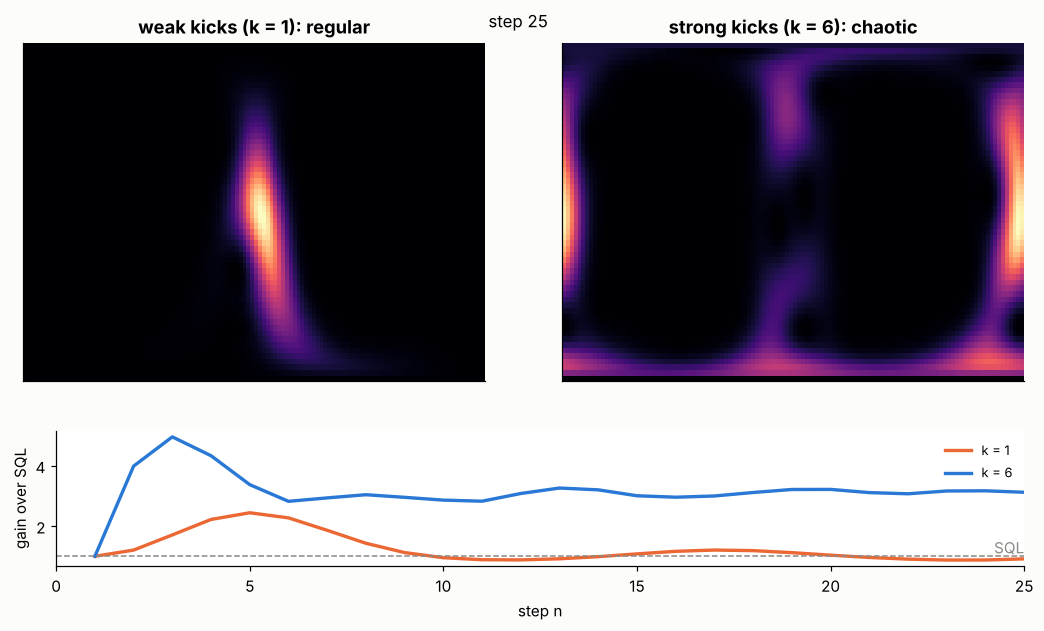

saved qe015_chaotic_sensor.gif (28 s)


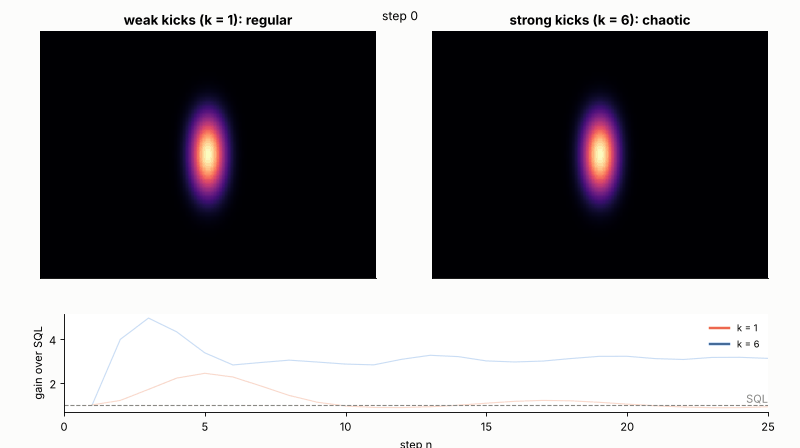

## Conclusions

1. **Exact answer.** For $j = 10$, $k = 6$, $\theta = 0.1$, 20 steps from $+x$, the quantum Fisher information is
   $F = 14186.14\ldots$, so $A = 14186139$, confirmed by finite differences. That is 1.77 times the standard quantum
   limit, from a completely unentangled input.
2. **Chaos can beat the SQL.** Strong kicks push the information well above $N n^2$ for well-chosen starting states.
3. **Starting state matters.** The gain map mirrors the classical phase-space map: inside regular islands the sensor
   is poor, and the best points sit in the chaotic region next to them.
4. **The advantage grows with sensor size**, but stays far from the Heisenberg limit.
5. **Noise is the price.** Chaos amplifies noise as well as signal, so the advantage shrinks and eventually disappears
   as dephasing grows.

**Try it yourself:** let the kick strength vary from step to step and optimise it, add a realistic measurement
(e.g. of $J_z$) and compare its classical Fisher information with the QFI, or use superradiant damping instead of
dephasing.

### Further reading

* L. J. Fiderer, D. Braun, *Quantum metrology with quantum-chaotic sensors*, Nature Communications 9, 1351 (2018).
* D. Braun, G. Adesso, F. Benatti, R. Floreanini, U. Marzolino, M. W. Mitchell, S. Pirandola, *Quantum-enhanced
  measurements without entanglement*, Rev. Mod. Phys. 90, 035006 (2018).
* L. J. Fiderer, J. M. E. Fraïsse, D. Braun, *Maximal quantum Fisher information for mixed states*, Phys. Rev. Lett.
  123, 250502 (2019).
* F. Haake, *Quantum Signatures of Chaos*, Springer (2010).
* V. Giovannetti, S. Lloyd, L. Maccone, *Advances in quantum metrology*, Nature Photonics 5, 222 (2011).